In [1]:
import difflib
import io
import json
import re
import sys
import time
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
import xlrd
import yfinance as yf
from openpyxl import load_workbook

from mf_lakehouse.common.config import PROJECT_ROOT, get_env

In [2]:
print(sys.executable)
print(pd.__version__)
print(get_env("DATABRICKS_CATALOG"))

/home/janardhan/Desktop/projects/mf-lakehouse/.venv/bin/python
3.1.0
mf_lakehouse


In [3]:
# Pinned to the snapshot explored on Day 2, so results are reproducible.
SNAPSHOT = "2026-11-01"
URL = "https://www.amfiindia.com/spages/NAVAll.txt"
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "amfi"
RAW_DIR.mkdir(parents=True, exist_ok=True)
raw_path = RAW_DIR / f"NAVAll_{SNAPSHOT}.txt"

if not raw_path.exists():
    resp = requests.get(
        URL,
        timeout=60,
        headers={"User-Agent": "mf-lakehouse portfolio project"},
    )
    resp.raise_for_status()
    raw_path = RAW_DIR / f"NAVAll_{date.today():%Y-%m-%d}.txt"
    raw_path.write_bytes(resp.content)
    print("Snapshot missing, downloaded a new one:", raw_path.name)

print("Using:", raw_path.name)
lines = raw_path.read_text(encoding="utf-8", errors="replace").splitlines()
print("Lines: ", len(lines))
for i, line in enumerate(lines[:15]):
    print(i, repr(line))

Using: NAVAll_2026-11-01.txt
Lines:  18230
0 'Scheme Code;ISIN Div Payout/ ISIN Growth;ISIN Div Reinvestment;Scheme Name;Plan;Option;Net Asset Value;Date'
1 ' '
2 "Open Ended Schemes(Children’s Fund - Childrens' Fund)"
3 ' '
4 'Axis Mutual Fund'
5 ' '
6 "135762;INF846K01WO1;-;Axis Children's Fund;Direct Plan;Growth Option;29.1949;30-Oct-2026"
7 "135765;INF846K01WP8;-;Axis Children's Fund;Direct Plan;IDCW Option;26.8938;30-Oct-2026"
8 "135759;INF846K01WJ1;-;Axis Children's Fund;Regular Plan;Growth Option;25.3963;30-Oct-2026"
9 "135760;INF846K01WK9;-;Axis Children's Fund;Regular Plan;IDCW Option;23.4301;30-Oct-2026"
10 "135764;INF846K01WR4;-;Axis Children's Fund;Direct Plan;Growth Option;29.7532;30-Oct-2026"
11 "135763;INF846K01WS2;INF846K01WQ6;Axis Children's Fund;Direct Plan;IDCW Option;26.9446;30-Oct-2026"
12 "135766;INF846K01WM5;-;Axis Children's Fund;Regular Plan;Growth Option;25.3932;30-Oct-2026"
13 "135761;INF846K01WN3;INF846K01WL7;Axis Children's Fund;Regular Plan;IDCW Option;23.

In [4]:
data_lines = [l for l in lines if ";" in l]
other_lines = [l for l in lines if l.strip() and ";" not in l]
blank_lines = [l for l in lines if not l.strip()]

print("Lines with ';':   ", len(data_lines))
print("Lines without ';':", len(other_lines))
print("Blank lines:      ", len(blank_lines))
print()
print("Sample non-data lines:")
for l in other_lines[:10]:
    print("  ", repr(l))

Lines with ';':    14442
Lines without ';': 1297
Blank lines:       2491

Sample non-data lines:
   "Open Ended Schemes(Children’s Fund - Childrens' Fund)"
   'Axis Mutual Fund'
   'Open Ended Schemes(Debt Scheme - Banking and PSU Fund)'
   'Franklin Templeton Mutual Fund'
   'HDFC Mutual Fund'
   'ITI Mutual Fund'
   'Kotak Mahindra Mutual Fund'
   'Open Ended Schemes(Debt Scheme - Corporate Bond Fund)'
   'Aditya Birla Sun Life Mutual Fund'
   'Bandhan Mutual Fund'


In [5]:
COLS = [
    "scheme_code", "isin_growth_or_payout", "isin_reinvestment",
    "scheme_name", "plan", "option", "nav", "nav_date",
]
CATEGORY_RE = re.compile(r"^(Open Ended|Close Ended|Interval Fund)\s+Schemes", re.I)

rows, bad_rows, odd_headings = [], [], set()
category = amc = None

for line in lines[1:]:
    s = line.strip()
    if not s:
        continue
    if ";" in s:
        parts = [p.strip() for p in s.split(";")]
        if len(parts) != len(COLS):
            bad_rows.append(s)
            continue
        rows.append(parts + [category, amc])
    elif CATEGORY_RE.match(s):
        category = s
    else:
        amc = s
        if not s.endswith("Mutual Fund"):
            odd_headings.add(s)

nav = pd.DataFrame(rows, columns=COLS + ["category_raw", "amc"])
print("Shape:", nav.shape)
print("Rows with wrong column count:", len(bad_rows))
print("Headings treated as fund houses but not ending in 'Mutual Fund':")
for h in sorted(odd_headings)[:20]:
    print("  ", repr(h))
nav.head()

Shape: (14441, 10)
Rows with wrong column count: 0
Headings treated as fund houses but not ending in 'Mutual Fund':
   'ASK MUTUAL FUND'
   'IL&FS Mutual Fund (IDF)'


,scheme_code,isin_growth_or_payout,isin_reinvestment,scheme_name,plan,option,nav,nav_date,category_raw,amc
0,135762,INF846K01WO1,-,Axis Children's Fund,Direct Plan,Growth Option,29.1949,30-Oct-2026,Open Ended Schemes(Children’s Fund - Childrens...,Axis Mutual Fund
1,135765,INF846K01WP8,-,Axis Children's Fund,Direct Plan,IDCW Option,26.8938,30-Oct-2026,Open Ended Schemes(Children’s Fund - Childrens...,Axis Mutual Fund
2,135759,INF846K01WJ1,-,Axis Children's Fund,Regular Plan,Growth Option,25.3963,30-Oct-2026,Open Ended Schemes(Children’s Fund - Childrens...,Axis Mutual Fund
3,135760,INF846K01WK9,-,Axis Children's Fund,Regular Plan,IDCW Option,23.4301,30-Oct-2026,Open Ended Schemes(Children’s Fund - Childrens...,Axis Mutual Fund
4,135764,INF846K01WR4,-,Axis Children's Fund,Direct Plan,Growth Option,29.7532,30-Oct-2026,Open Ended Schemes(Children’s Fund - Childrens...,Axis Mutual Fund


In [6]:
nav_num = pd.to_numeric(nav["nav"], errors="coerce")

print("Rows:", len(nav), "| distinct scheme codes:", nav["scheme_code"].nunique())
print("Duplicate scheme codes:", nav["scheme_code"].duplicated().sum())
print("Rows sharing name + plan + option:",
      nav.duplicated(["scheme_name", "plan", "option"], keep=False).sum())
print()
print("Non-numeric NAV values:")
print(nav.loc[nav_num.isna(), "nav"].value_counts().head(10))
print()
print("NAV dates:")
print(nav["nav_date"].value_counts().head(10))
print()
print(nav["plan"].value_counts())
print()
print(nav["option"].value_counts().head(10))

Rows: 14441 | distinct scheme codes: 14441
Duplicate scheme codes: 0
Rows sharing name + plan + option: 5947

Non-numeric NAV values:
Series([], Name: count, dtype: int64)

NAV dates:
nav_date
30-Oct-2026    7238
31-Oct-2026     813
01-Nov-2026     712
02-Jul-2018     113
16-Sep-2022      76
24-Apr-2020      66
11-Apr-2022      60
27-Jan-2022      55
10-May-2021      54
19-Apr-2022      53
Name: count, dtype: int64

plan
                5709
Regular Plan    4374
Direct Plan     4358
Name: count, dtype: int64

option
                                                     5715
Growth                                               2118
IDCW                                                 1461
Growth Option                                        1190
IDCW Option                                           683
GROWTH                                                266
Monthly IDCW                                          225
IDCW (Income Distribution CUM Capital Withdrawal)     154
Quarterly IDCW

In [7]:
nav["nav_date_parsed"] = pd.to_datetime(nav["nav_date"], format="%d-%b-%Y")
latest = nav["nav_date_parsed"].max()
age_days = (latest - nav["nav_date_parsed"]).dt.days

print("Newest NAV date in file:", latest.date())
print(pd.cut(
    age_days,
    bins=[-1, 3, 30, 365, 100_000],
    labels=["0-3 days", "4-30 days", "31-365 days", "over 1 year"],
).value_counts().sort_index())
print()

weekend = nav["nav_date_parsed"].dt.day_of_week >= 5
print("Categories of rows dated on a weekend:")
print(nav.loc[weekend, "category_raw"].value_counts().head(10))

Newest NAV date in file: 2026-11-01
nav_date_parsed
0-3 days       8802
4-30 days        21
31-365 days     230
over 1 year    5388
Name: count, dtype: int64

Categories of rows dated on a weekend:
category_raw
Open Ended Schemes(Debt Scheme - Liquid Fund)                               240
Open Ended Schemes(Income/Debt Oriented Schemes - Liquid Fund)              183
Open Ended Schemes(Debt Scheme - Overnight Fund)                            179
Open Ended Schemes(Other Scheme - Index Funds)                              158
Open Ended Schemes(Income/Debt Oriented Schemes - Overnight Fund)           106
Open Ended Schemes(Equity Scheme - Sectoral/ Thematic)                       60
Close Ended Schemes(Income)                                                  53
Open Ended Schemes(Other Scheme - FoF Domestic)                              40
Open Ended Schemes(Other Scheme - Other  ETFs)                               34
Open Ended Schemes(Income/Debt Oriented Schemes - Ultra Short Term Fu

In [8]:
blank_plan = nav["plan"] == ""
print("Blank-plan rows:", blank_plan.sum())
print("...of which older than 30 days:", (blank_plan & (age_days > 30)).sum())
print()
print(nav.loc[blank_plan, ["scheme_name", "option", "nav_date"]]
         .sample(10, random_state=1)
         .to_string())
print()
print("Distinct categories:", nav["category_raw"].nunique())

Blank-plan rows: 5709
...of which older than 30 days: 5176

                                                                   scheme_name option     nav_date
13157                            Reliance Fixed Horizon Fund - XXVI - Series 2         07-Apr-2015
13456                             Reliance Fixed Horizon Fund- XXVI- Series 12         25-Apr-2017
10995      ICICI Prudential Fixed Maturity Plan - Series 81 - 1205 Days Plan B         11-Aug-2020
1179   Franklin India Short-Term Income Plan (no. of segregated portfolios- 3)         20-Jul-2020
9793                 SUNDARAM LONG TERM MICRO CAP TAX ADVANTAGE FUND SERIES VI         30-Oct-2026
9438                            Motilal Oswal Nifty 5 year benchmark G-Sec ETF         30-Oct-2026
9942                                   ICICI Prudential Value Fund - Series 18         17-May-2021
12783                        Nippon India Fixed Horizon Fund XXXVIII- Series 6         17-Aug-2021
14052                            UTI - FTIF - Ser

In [9]:
HIST_URL = "https://portal.amfiindia.com/DownloadNAVHistoryReport_Po.aspx"

to_dt = date(2026, 10, 30)
from_dt = to_dt - timedelta(days=6)

resp_h = requests.get(
    HIST_URL,
    params={
        "tp": "1",
        "frmdt": from_dt.strftime("%d-%b-%Y"),
        "todt": to_dt.strftime("%d-%b-%Y"),
    },
    timeout=120,
    headers={"User-Agent": "mf-lakehouse portfolio project"},
)
print("URL:   ", resp_h.url)
print("Status:", resp_h.status_code)
print("Type:  ", resp_h.headers.get("Content-Type"))
print("Size:  ", len(resp_h.content), "bytes")

hist_lines = resp_h.content.decode("utf-8", errors="replace").splitlines()
print("Lines: ", len(hist_lines))
for i, line in enumerate(hist_lines[:12]):
    print(i, repr(line))

URL:    https://portal.amfiindia.com/DownloadNAVHistoryReport_Po.aspx?tp=1&frmdt=24-Oct-2026&todt=30-Oct-2026
Status: 200
Type:   text/plain
Size:   5883989 bytes
Lines:  46994
0 'Scheme Code;NAV Name;Plan;Option;ISIN Div Payout/ISIN Growth;ISIN Div Reinvestment;Net Asset Value;Date'
1 ''
2 'Open Ended Schemes ( Equity Scheme - Multi Cap Fund )'
3 ''
4 ''
5 'Aditya Birla Sun Life Mutual Fund'
6 '148921;Aditya Birla Sun Life Multi-Cap Fund-Direct Growth;Direct Plan;GROWTH;INF209KB1Y49;;21.24;26-Oct-2026'
7 '148921;Aditya Birla Sun Life Multi-Cap Fund-Direct Growth;Direct Plan;GROWTH;INF209KB1Y49;;21.47;27-Oct-2026'
8 '148921;Aditya Birla Sun Life Multi-Cap Fund-Direct Growth;Direct Plan;GROWTH;INF209KB1Y49;;21.57;28-Oct-2026'
9 '148921;Aditya Birla Sun Life Multi-Cap Fund-Direct Growth;Direct Plan;GROWTH;INF209KB1Y49;;21.75;29-Oct-2026'
10 '148921;Aditya Birla Sun Life Multi-Cap Fund-Direct Growth;Direct Plan;GROWTH;INF209KB1Y49;;21.63;30-Oct-2026'
11 '148920;Aditya Birla Sun Life Multi

In [10]:
COLUMN_MAP = {
    "Scheme Code": "scheme_code",
    "Scheme Name": "scheme_name",
    "NAV Name": "scheme_name",
    "ISIN Div Payout/ ISIN Growth": "isin_growth_or_payout",
    "ISIN Div Payout/ISIN Growth": "isin_growth_or_payout",
    "ISIN Div Reinvestment": "isin_reinvestment",
    "Plan": "plan",
    "Option": "option",
    "Net Asset Value": "nav",
    "Date": "nav_date",
}


def clean_heading(s: str) -> str:
    s = " ".join(s.split())                 # collapse repeated spaces
    s = re.sub(r"\s*\(\s*", "(", s)         # "Schemes ( Equity" -> "Schemes(Equity"
    return re.sub(r"\s*\)", ")", s)         # "Fund )" -> "Fund)"


def parse_amfi(text_lines):
    header = [h.strip() for h in text_lines[0].split(";")]
    unknown = [h for h in header if h not in COLUMN_MAP]
    if unknown:
        raise ValueError(f"Unknown columns: {unknown}")

    rows, category, amc = [], None, None
    for line in text_lines[1:]:
        s = line.strip()
        if not s:
            continue
        if ";" in s:
            parts = [p.strip() for p in s.split(";")]
            if len(parts) != len(header):
                raise ValueError(f"Bad row: {s!r}")
            rows.append(parts + [category, amc])
        elif CATEGORY_RE.match(s):
            category = clean_heading(s)
        else:
            amc = s

    df = pd.DataFrame(rows, columns=header + ["category_raw", "amc"])
    df = df.rename(columns=COLUMN_MAP)
    return df.replace({"isin_growth_or_payout": {"-": None, "": None},
                       "isin_reinvestment": {"-": None, "": None}})


daily = parse_amfi(lines)
hist = parse_amfi(hist_lines)

print("Daily:", daily.shape, "| History:", hist.shape)
print("Same columns:", sorted(daily.columns) == sorted(hist.columns))
print("History duplicate (scheme_code, nav_date):",
      hist.duplicated(["scheme_code", "nav_date"]).sum())
print("History dates:")
print(hist["nav_date"].value_counts().sort_index())

Daily: (14441, 10) | History: (44433, 10)
Same columns: True
History duplicate (scheme_code, nav_date): 0
History dates:
nav_date
24-Oct-2026     608
25-Oct-2026     714
26-Oct-2026    8593
27-Oct-2026    8622
28-Oct-2026    8621
29-Oct-2026    8638
30-Oct-2026    8637
Name: count, dtype: int64


In [11]:
d = daily[daily["nav_date"] == "30-Oct-2026"]
h = hist[hist["nav_date"] == "30-Oct-2026"]

m = d.merge(h, on=["scheme_code", "nav_date"], how="outer",
            suffixes=("_daily", "_hist"), indicator=True)
print(m["_merge"].value_counts())

both = m[m["_merge"] == "both"].copy()
diff = (pd.to_numeric(both["nav_daily"]) - pd.to_numeric(both["nav_hist"])).abs()
print()
print("NAV mismatches (> 0.0001):", (diff > 0.0001).sum(), "of", len(both))
print("Name differs:     ", (both["scheme_name_daily"] != both["scheme_name_hist"]).sum())
print("Category differs: ", (both["category_raw_daily"] != both["category_raw_hist"]).sum())
print()
print(both.loc[diff > 0.0001, ["scheme_code", "nav_daily", "nav_hist"]].head(10).to_string())

_merge
both          7130
right_only    1507
left_only      108
Name: count, dtype: int64

NAV mismatches (> 0.0001): 8 of 7130
Name differs:      6847
Category differs:  0

     scheme_code  nav_daily   nav_hist
1211      117446  2790.0283  2790.3836
1212      117447  1033.5860  1033.7176
1213      117448  1033.1847  1033.3162
1214      117449  1030.6122  1030.7435
2109      120436  1033.7804  1033.9120
2110      120437  1034.2042  1034.3359
2111      120438  2887.8469  2888.2147
2112      120439  1031.0041  1031.1354


In [12]:
right_codes = m.loc[m["_merge"] == "right_only", "scheme_code"]
left_codes = m.loc[m["_merge"] == "left_only", "scheme_code"]

# 1. History-only: what date does the daily file have for these schemes?
print("1. Daily-file dates for history-only schemes:")
print(daily.loc[daily["scheme_code"].isin(right_codes), "nav_date"]
           .value_counts().head())
print("   ...not in daily file at all:",
      (~right_codes.isin(daily["scheme_code"])).sum())
print()

# 2. Daily-only: which categories?
print("2. Categories of daily-only schemes:")
print(d.loc[d["scheme_code"].isin(left_codes), "category_raw"]
       .str.split("(").str[0].value_counts())
print()

# 3. Names side by side
print("3. Name samples:")
print(both[["scheme_name_daily", "plan_daily", "option_daily", "scheme_name_hist"]]
      .sample(5, random_state=2).to_string())

1. Daily-file dates for history-only schemes:
nav_date
31-Oct-2026    757
01-Nov-2026    712
29-Oct-2026     38
Name: count, dtype: int64
   ...not in daily file at all: 0

2. Categories of daily-only schemes:
category_raw
Close Ended Schemes      104
Interval Fund Schemes      4
Name: count, dtype: int64

3. Name samples:
                                                                scheme_name_daily    plan_daily                                       option_daily                                                                                 scheme_name_hist
7144  Aditya Birla Sun Life Crisil-IBX AAA Financial Services Index-Sep 2027 Fund  Regular Plan                                        IDCW Payout  Aditya Birla Sun Life Crisil-IBX AAA Financial Services Index-Sep 2027 Fund-Regular IDCW Payout
5521                                             ICICI PRUDENTIAL PSU EQUITY FUND  Regular Plan                                               IDCW                                         

In [13]:
idx = yf.download(
    ["^NSEI", "^BSESN"],
    start="2024-10-01",
    end="2026-11-01",
    auto_adjust=False,
    group_by="ticker",
    progress=False,
)

print("Shape:", idx.shape)
print("Columns:", list(idx.columns)[:8])
print("Index type:", type(idx.index).__name__, "| tz:", idx.index.tz)
print("Range:", idx.index.min().date(), "->", idx.index.max().date())
print()

for t in ["^NSEI", "^BSESN"]:
    close = idx[t]["Close"]
    print(f"{t}: rows with a close = {close.notna().sum()}, missing = {close.isna().sum()}")

both_dates = idx[["^NSEI", "^BSESN"]].xs("Close", axis=1, level=1)
only_one = both_dates.notna().sum(axis=1) == 1
print()
print("Days where only one index has a close:", only_one.sum())
print(both_dates[only_one].head().to_string())
print()
print(idx.tail(3).to_string())

Shape: (515, 12)
Columns: [('^BSESN', 'Open'), ('^BSESN', 'High'), ('^BSESN', 'Low'), ('^BSESN', 'Close'), ('^BSESN', 'Adj Close'), ('^BSESN', 'Volume'), ('^NSEI', 'Open'), ('^NSEI', 'High')]
Index type: DatetimeIndex | tz: None
Range: 2024-10-01 -> 2026-10-30

^NSEI: rows with a close = 515, missing = 0
^BSESN: rows with a close = 514, missing = 1

Days where only one index has a close: 1
Ticker             ^NSEI  ^BSESN
Date                            
2025-02-01  23482.150391     NaN

Ticker           ^BSESN                                                                         ^NSEI                                                                
Price              Open         High           Low         Close     Adj Close   Volume          Open          High           Low         Close     Adj Close  Volume
Date                                                                                                                                                                 
2026-10-2

/home/janardhan/Desktop/projects/mf-lakehouse/.venv/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/janardhan/Desktop/projects/mf-lakehouse/.venv/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/janardhan/Desktop/projects/mf-lakehouse/.venv/lib/python3.12/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.h

AUM report is legacy .xls (CDF V2, code page 1252). openpyxl can’t read it → use xlrd.

In [14]:
AUM_DIR = PROJECT_ROOT / "data" / "raw" / "aum"
files = sorted(AUM_DIR.glob("*.xls*"))
if not files:
    raise FileNotFoundError(f"No .xls/.xlsx file in {AUM_DIR}")
aum_path = files[-1]
print("File:", aum_path.name)

book = xlrd.open_workbook(aum_path, formatting_info=True)
for sh in book.sheets():
    print(f"\nSheet: {sh.name!r} | rows={sh.nrows} cols={sh.ncols} "
          f"| merged ranges={len(sh.merged_cells)}")
    for r in range(min(12, sh.nrows)):
        cells = [v for v in sh.row_values(r) if v not in ("", None)]
        if cells:
            print(f"  row {r}: {cells[:8]}")

File: amsep2026repo.xls

Sheet: 'MCR_MonthlyReport' | rows=110 cols=11 | merged ranges=4
  row 1: ['Monthly Report for the month of September 2026 ']
  row 2: ['Sr ', 'Scheme Name ', 'No. of Schemes as on September 30, 2026', 'No. of Folios as on September 30, 2026', 'Funds Mobilized for the month of September 2026 (INR in crore)', 'Repurchase/Redemption for the month of September 2026 (INR in crore)', 'Net Inflow (+ve)/Outflow (-ve) for the month of September 2026 (INR in crore)', 'Net Assets Under Management as on September 30, 2026 (INR in crore)']
  row 3: ['A', 'Open ended Schemes']
  row 4: ['I', 'Debt Schemes']
  row 5: ['i', 'Overnight Fund', 40.0, 820060.0, 720356.24836343, 727637.44419465, -7281.19583121967, 84032.57445358]
  row 6: ['ii', 'Liquid Fund', 43.0, 4129998.0, 543731.2220959, 639474.42486608, -95743.2027701796, 625847.00810743]
  row 7: ['iii', 'Ultra Short Term Fund', 26.0, 787333.0, 20073.04987896, 31801.91892911, -11728.86905015, 120693.10446163]
  row 8: ['iv',

In [15]:
sh = book.sheet_by_name("MCR_MonthlyReport")

print("Full header (row 2):")
for c, h in enumerate(sh.row_values(2)):
    print(f"  col {c}: {h!r}")
print()

for r in range(3, sh.nrows):
    row = sh.row_values(r)
    label = (str(row[0]).strip(), str(row[1]).strip())
    numbers = sum(isinstance(v, float) for v in row[2:])
    print(f"row {r:>3} | {label[0]:<5} | {label[1][:60]:<60} | numeric cells: {numbers}")

Full header (row 2):
  col 0: 'Sr '
  col 1: 'Scheme Name '
  col 2: 'No. of Schemes as on September 30, 2026'
  col 3: 'No. of Folios as on September 30, 2026'
  col 4: 'Funds Mobilized for the month of September 2026 (INR in crore)'
  col 5: 'Repurchase/Redemption for the month of September 2026 (INR in crore)'
  col 6: 'Net Inflow (+ve)/Outflow (-ve) for the month of September 2026 (INR in crore)'
  col 7: 'Net Assets Under Management as on September 30, 2026 (INR in crore)'
  col 8: 'Average Net Assets Under Management for the month September 2026 (INR in crore)'
  col 9: 'No. of segregated portfolios created as on September 30, 2026'
  col 10: 'Net Assets Under Management in segregated portfolio as on September 30, 2026 (INR in crore)'

row   3 | A     | Open ended Schemes                                           | numeric cells: 0
row   4 | I     | Debt Schemes                                                 | numeric cells: 0
row   5 | i     | Overnight Fund                    

In [16]:
NUM_COLS = [
    "num_schemes", "num_folios", "funds_mobilized_inr_cr", "redemption_inr_cr",
    "net_flow_inr_cr", "net_aum_inr_cr", "avg_net_aum_inr_cr",
    "segregated_portfolios", "segregated_net_aum_inr_cr",
]
TYPE_CODES = {"A", "B", "C"}

# --- Footnotes and '##' markers in full ---
for r in range(sh.nrows):
    text = " | ".join(str(v) for v in sh.row_values(r) if str(v).strip())
    if "**" in text or "##" in text:
        print(f"row {r}: {text}")
print()

# --- Parse leaf rows, carrying type and class down ---
rows, scheme_type, scheme_class = [], None, None
for r in range(3, sh.nrows):
    v = sh.row_values(r)
    code = str(v[0]).strip()
    name = " ".join(str(v[1]).split())
    if code in TYPE_CODES:
        scheme_type, scheme_class = name, None      # new type resets the class
    elif re.fullmatch(r"[IVX]+", code):
        scheme_class = name
    elif re.fullmatch(r"[ivx]+", code):
        rows.append({"scheme_type": scheme_type, "scheme_class": scheme_class,
                     "category": name, **dict(zip(NUM_COLS, v[2:11]))})

aum = pd.DataFrame(rows)
aum[NUM_COLS] = aum[NUM_COLS].apply(pd.to_numeric, errors="coerce")
print("Leaf categories:", len(aum))
print("Duplicate category names:", aum.loc[aum["category"].duplicated(), "category"].tolist())
print("Duplicate (type, class, category):",
      aum.duplicated(["scheme_type", "scheme_class", "category"]).sum())
print()

# --- Reconcile leaves against the report's own totals ---
def total_row(label):
    for r in range(sh.nrows):
        if " ".join(str(sh.cell_value(r, 1)).split()).lower() == label.lower():
            return pd.to_numeric(pd.Series(sh.row_values(r)[2:11], index=NUM_COLS), errors="coerce")
    raise ValueError(f"Total row not found: {label}")

checks = {
    "Grand Total": aum,
    "Total A-Open ended Schemes": aum[aum["scheme_type"].str.startswith("Open")],
    "Total B -Close ended Schemes": aum[aum["scheme_type"].str.startswith("Close")],
    "Total C Interval Schemes": aum[aum["scheme_type"].str.startswith("Interval")],
}
for label, part in checks.items():
    diff = (part[NUM_COLS].sum() - total_row(label)).abs()
    worst = diff.max()
    print(f"{label:<30} rows={len(part):>2}  max abs diff={worst:,.6f}  "
          f"{'OK' if worst < 0.01 else 'MISMATCH in ' + diff.idxmax()}")

row 59: V | Solution Oriented Schemes **
row 106: Fund of Funds Scheme (Domestic) ** | # 158 | 14255246.0 | 5818.15548498 | 3455.28921736 | 2362.86626762 | 224979.49017943 | 232776.74754603 | 0.0 | 0.0
row 108: ** Data in respect Fund of Funds Domestic is shown for information only. The same is included in the respective underlying schemes.
row 109: ## Include NFOs-  Nippon India Income Plus Arbitrage Omni Fund of Fund, quant Income Plus Arbitrage Active FOF,HDFC GOLD SILVER PASSIVE FOF, Kotak Multi Sector Omni FOF,ICICI Prudential Dynamic Asset Allocation Passive FOF, Shriram Gold ETF Passive FOF

Leaf categories: 61
Duplicate category names: ['Sectoral Fund']
Duplicate (type, class, category): 0

Grand Total                    rows=61  max abs diff=0.000000  OK
Total A-Open ended Schemes     rows=56  max abs diff=0.000000  OK
Total B -Close ended Schemes   rows= 4  max abs diff=0.000000  OK
Total C Interval Schemes       rows= 1  max abs diff=0.000000  OK


In [17]:
print("NaN cells in leaf rows:")
print(aum[NUM_COLS].isna().sum().to_string())
print()

raw_text_numbers = [
    (r, c, sh.cell_value(r, c))
    for r in range(3, sh.nrows)
    for c in range(2, 11)
    if isinstance(sh.cell_value(r, c), str) and sh.cell_value(r, c).strip()
]
print("Numeric-column cells containing text:", raw_text_numbers)

aum["category"] = aum["category"].str.replace(r"[#*]+", "", regex=True).str.strip()
aum["scheme_class"] = aum["scheme_class"].str.replace(r"[#*]+", "", regex=True).str.strip()
print()
print(aum[["scheme_type", "scheme_class", "category"]].drop_duplicates("scheme_class").to_string())

NaN cells in leaf rows:
num_schemes                  0
num_folios                   0
funds_mobilized_inr_cr       0
redemption_inr_cr            0
net_flow_inr_cr              0
net_aum_inr_cr               0
avg_net_aum_inr_cr           0
segregated_portfolios        0
segregated_net_aum_inr_cr    0

Numeric-column cells containing text: [(106, 2, '# 158')]

            scheme_type                    scheme_class                                  category
0    Open ended Schemes                    Debt Schemes                            Overnight Fund
17   Open ended Schemes                  Equity Schemes                            Multi Cap Fund
30   Open ended Schemes                  Hybrid Schemes                  Conservative Hybrid Fund
37   Open ended Schemes                Life Cycle Funds  Life Cycle Fund with Maturity of 5 Years
43   Open ended Schemes       Solution Oriented Schemes                           Retirement Fund
45   Open ended Schemes                     Index

In [18]:
TER_API = "https://www.amfiindia.com/api/populate-te-rdata-revised"

params = {
    "MF_ID": "All",
    "Month": "10-2026",
    "strCat": "-1",
    "strType": "-1",
    "page": 1,
    "pageSize": 15,
}
resp_t = requests.get(
    TER_API,
    params=params,
    timeout=60,
    headers={"User-Agent": "mf-lakehouse portfolio project"},
)
print("Status:", resp_t.status_code)
print("Type:  ", resp_t.headers.get("Content-Type"))

js = resp_t.json()
print("Top-level type:", type(js).__name__)
if isinstance(js, dict):
    for k, v in js.items():
        print(f"  {k!r}: {type(v).__name__} {str(v)[:80]!r}")

Status: 200
Type:   application/json; charset=utf-8
Top-level type: dict
  'data': list "[{'NSDLSchemeCode': '360O/O/H/BHF/23/07/0007', 'Scheme_Name': '360 ONE Balanced "
  'meta': dict "{'page': 1, 'pageSize': 15, 'total': 64544, 'pageCount': 4303}"


In [19]:
first = js["data"][0]
print("Fields in one record:")
print(json.dumps(first, indent=2, ensure_ascii=False))
print()

for size in [100, 1000]:
    t0 = time.time()
    r = requests.get(
        TER_API,
        params={**params, "pageSize": size},
        timeout=120,
        headers={"User-Agent": "mf-lakehouse portfolio project"},
    )
    m = r.json()
    print(f"asked {size:>5} | got {len(m['data']):>5} records "
          f"| meta={m['meta']} | {time.time() - t0:.1f}s")
    time.sleep(1)

Fields in one record:
{
  "NSDLSchemeCode": "360O/O/H/BHF/23/07/0007",
  "Scheme_Name": "360 ONE Balanced Hybrid Fund",
  "SchemeType_Desc": "Open Ended",
  "SchemeCat_Desc": "Hybrid Schemes - Balanced Hybrid Fund",
  "TER_Year": "2026-2027",
  "TER_Date": "2026-10-01T00:00:00.000Z",
  "R_BER": "1.7800",
  "R_BrokerageCost": "0.0300",
  "R_TransactionCost": "0.0000",
  "R_StatutoryLevies": "0.3800",
  "R_TER": "2.1900",
  "D_BER": "0.4500",
  "D_BrokerageCost": "0.0300",
  "D_TransactionCost": "0.0000",
  "D_StatutoryLevies": "0.1400",
  "D_TER": "0.6200",
  "MF_ID": 62,
  "Month": "10-2026"
}

asked   100 | got   100 records | meta={'page': 1, 'pageSize': 100, 'total': 64544, 'pageCount': 646} | 11.2s
asked  1000 | got   100 records | meta={'page': 1, 'pageSize': 100, 'total': 64544, 'pageCount': 646} | 11.9s


TER API caps pageSize at 100 (asked 1000, got 100, which would mean 646 requests per month). The page’s Excel button uses excel=true, which returns the full month in one request; see below.

In [20]:
ter_files = sorted((PROJECT_ROOT / "data" / "raw" / "ter").glob("*.xlsx"))
if not ter_files:
    raise FileNotFoundError("No .xlsx file in data/raw/ter")
ter_xlsx = ter_files[-1]
print("File:", ter_xlsx.name)

wb_t = load_workbook(ter_xlsx, read_only=True, data_only=True)
for ws in wb_t.worksheets:
    print(f"\nSheet {ws.title!r}: rows={ws.max_row}, cols={ws.max_column}")
    for r, row in enumerate(ws.iter_rows(min_row=1, max_row=6, values_only=True), start=1):
        print(f"  row {r}: {[c for c in row if c is not None][:10]}")

File: ter-of-mf-schemes.xlsx

Sheet 'TER_Revised': rows=None, cols=None
  row 1: ['NSDL Scheme Code', 'Scheme Name', 'Scheme Type', 'Scheme Category', 'TER Date', 'Regular Plan - Base Expense Ratio (BER) (%)', 'Regular Plan - Brokerage cost (%)', 'Regular Plan - Transaction Cost incurred for the purpose of execution of trade (%)', 'Regular Plan - Statutory Levies (including GST) (%)', 'Regular Plan - Total TER (%)']
  row 2: ['360O/O/H/BHF/23/07/0007', '360 ONE Balanced Hybrid Fund', 'Open Ended', 'Hybrid Schemes - Balanced Hybrid Fund', datetime.datetime(2026, 10, 1, 0, 0), 1.78, 0.03, 0, 0.38, 2.19]
  row 3: ['360O/O/H/BHF/23/07/0007', '360 ONE Balanced Hybrid Fund', 'Open Ended', 'Hybrid Schemes - Balanced Hybrid Fund', datetime.datetime(2026, 10, 2, 0, 0), 1.78, 0.03, 0, 0.38, 2.19]
  row 4: ['360O/O/H/BHF/23/07/0007', '360 ONE Balanced Hybrid Fund', 'Open Ended', 'Hybrid Schemes - Balanced Hybrid Fund', datetime.datetime(2026, 10, 3, 0, 0), 1.78, 0.03, 0, 0.38, 2.19]
  row 5: ['36

In [21]:
ter_x = pd.read_excel(ter_xlsx, sheet_name="TER_Revised")

print("Shape:", ter_x.shape)
print("Columns:")
for c in ter_x.columns:
    print("  ", repr(c))
print()
print("Distinct days:", ter_x["TER Date"].nunique(),
      "|", ter_x["TER Date"].min().date(), "->", ter_x["TER Date"].max().date())
print("Distinct NSDL codes:", ter_x["NSDL Scheme Code"].nunique())
print("Duplicate (code, date):",
      ter_x.duplicated(["NSDL Scheme Code", "TER Date"]).sum())

r_total = ter_x["Regular Plan - Total TER (%)"]
r_parts = ter_x[[c for c in ter_x.columns
                 if c.startswith("Regular Plan") and "Total" not in c]].sum(axis=1)
print("Regular rows where parts don't sum to total (> 0.005):",
      ((r_parts - r_total).abs() > 0.005).sum())

Shape: (64555, 15)
Columns:
   'NSDL Scheme Code'
   'Scheme Name'
   'Scheme Type'
   'Scheme Category'
   'TER Date'
   'Regular Plan - Base Expense Ratio (BER) (%)'
   'Regular Plan - Brokerage cost (%)'
   'Regular Plan - Transaction Cost incurred for the purpose of execution of trade (%)'
   'Regular Plan - Statutory Levies (including GST) (%)'
   'Regular Plan - Total TER (%)'
   'Direct Plan - Base Expense Ratio (BER) (%)'
   'Direct Plan - Brokerage cost (%)'
   'Direct Plan - Transaction Cost incurred for the purpose of execution of trade (%)'
   'Direct Plan - Statutory Levies (including GST) (%)'
   'Direct Plan - Total TER (%)'

Distinct days: 31 | 2026-10-01 -> 2026-10-31
Distinct NSDL codes: 2188
Duplicate (code, date): 0
Regular rows where parts don't sum to total (> 0.005): 0


In [22]:
d_total = ter_x["Direct Plan - Total TER (%)"]
d_parts = ter_x[[c for c in ter_x.columns
                 if c.startswith("Direct Plan") and "Total" not in c]].sum(axis=1)
print("Direct rows where parts don't sum to total (> 0.005):",
      ((d_parts - d_total).abs() > 0.005).sum())
print()
print("Missing values per column:")
print(ter_x.isna().sum()[lambda s: s > 0].to_string())
print()

days_per_code = ter_x.groupby("NSDL Scheme Code")["TER Date"].nunique()
print("Schemes by number of days present:")
print(days_per_code.value_counts().sort_index(ascending=False).head(10).to_string())
print()

partial = days_per_code[days_per_code < 31].index
span = (ter_x[ter_x["NSDL Scheme Code"].isin(partial)]
        .groupby("NSDL Scheme Code")["TER Date"].agg(["min", "max", "count"]))
span["calendar_days"] = (span["max"] - span["min"]).dt.days + 1
span["gaps_inside"] = span["calendar_days"] - span["count"]
print("Partial schemes with gaps inside their own date range:",
      (span["gaps_inside"] > 0).sum(), "of", len(span))
print(span.sort_values("gaps_inside", ascending=False).head(5).to_string())

Direct rows where parts don't sum to total (> 0.005): 0

Missing values per column:
NSDL Scheme Code                                                                       1
Scheme Name                                                                           13
Scheme Type                                                                           13
Scheme Category                                                                       13
TER Date                                                                              13
Regular Plan - Base Expense Ratio (BER) (%)                                           13
Regular Plan - Brokerage cost (%)                                                     13
Regular Plan - Transaction Cost incurred for the purpose of execution of trade (%)    13
Regular Plan - Statutory Levies (including GST) (%)                                   13
Regular Plan - Total TER (%)                                                          13
Direct Plan - Base Expense

In [23]:
t0 = time.time()
r_all = requests.get(
    TER_API,
    params={
        "MF_ID": "All",
        "Month": "10-2026",
        "strCat": "-1",
        "strType": "-1",
        "excel": "true",
    },
    timeout=300,
    headers={"User-Agent": "mf-lakehouse portfolio project"},
)
print("Status:", r_all.status_code, f"| {time.time() - t0:.1f}s")
print("Type:  ", r_all.headers.get("Content-Type"))
print("Size:  ", f"{len(r_all.content) / 1e6:.1f} MB")
print("Starts with:", r_all.content[:20])

ctype = r_all.headers.get("Content-Type", "")
if "json" in ctype:
    body_all = r_all.json()
    data_all = body_all["data"] if isinstance(body_all, dict) else body_all
    print("JSON records:", len(data_all))
    if isinstance(body_all, dict):
        print("Top-level keys:", list(body_all.keys()), "| meta:", body_all.get("meta"))
elif r_all.content[:2] == b"PK":
    df_all = pd.read_excel(io.BytesIO(r_all.content))
    print("Excel rows:", len(df_all))
else:
    print("Unexpected format. First 300 bytes:", r_all.content[:300])

Status: 200 | 28.6s
Type:   application/vnd.openxmlformats-officedocument.spreadsheetml.sheet
Size:   4.5 MB
Starts with: b'PK\x03\x04\x14\x00\x08\x00\x08\x00\xe0\x88d]\x00\x00\x00\x00\x00\x00'
Excel rows: 64557


In [24]:
blank = ter_x["TER Date"].isna()
print("Rows with no TER Date:", blank.sum())
for v in ter_x.loc[blank, "NSDL Scheme Code"]:
    print("  ", repr(v)[:150])
print()

ter_c = ter_x[~blank].copy()
print("Clean rows:", len(ter_c), "| distinct codes:", ter_c["NSDL Scheme Code"].nunique())
print()

days = ter_c.groupby("NSDL Scheme Code")["TER Date"].nunique()
codes_20 = days[days == 20].index
d20 = ter_c.loc[ter_c["NSDL Scheme Code"].isin(codes_20), "TER Date"].drop_duplicates().sort_values()
print("Dates used by the 20-day schemes:", len(d20))
print("Any weekend dates among them:", (d20.dt.day_of_week >= 5).any())
print("Weekdays in October missing from them:")
all_weekdays = pd.bdate_range("2026-10-01", "2026-10-31")
print("  ", [d.date() for d in all_weekdays if d not in set(d20)])

Rows with no TER Date: 13
   nan
   'Disclaimer :'
   '1. Base Expense Ratio (BER) as per Regulation 66(7) of SEBI (Mutual Funds) Regulations, 2026.'
   '2. Brokerage Cost as per Regulation 66(9) of SEBI (Mutual Funds) Regulations, 2026. This represents annualized, cumulative daily average brokerage co
   '3. Transaction cost incurred for the purpose of execution of trade as referred under Regulation 66(10) of SEBI (Mutual Funds) Regulations, 2026. This
   '4. Statutory levies (including GST): Present GST rate is XX%. This has two parts:'
   '   a. GST on the Base TER; and'
   '   b. Statutory charges such as STT, GST on brokerage and stamp duty incurred for trade execution. This represents annualized, cumulative daily avera
   '5. Percentages mentioned above are annualized.'
   '6. Base Expense Ratio of direct plan shall have a lower expense ratio excluding distribution expenses, commission, etc., and no commission shall be p
   'Reference period:'
   'For April of a financial year (O

In [25]:
# --- Daily NAV with parsed dates, used for name matching and charts ---
raw_nav = raw_path
nav_lines = raw_nav.read_text(encoding="utf-8", errors="replace").splitlines()
header = [h.strip() for h in nav_lines[0].split(";")]
CAT_RE = re.compile(r"^(Open Ended|Close Ended|Interval Fund)\s+Schemes", re.I)

rows, amc = [], None
for line in nav_lines[1:]:
    s = line.strip()
    if not s:
        continue
    if ";" in s:
        rows.append([p.strip() for p in s.split(";")] + [amc])
    elif not CAT_RE.match(s):
        amc = s

daily = pd.DataFrame(rows, columns=header + ["amc"]).rename(columns={
    "Scheme Code": "scheme_code", "Scheme Name": "scheme_name", "Date": "nav_date"})
daily["nav_date"] = pd.to_datetime(daily["nav_date"], format="%d-%b-%Y")
active = daily[daily["nav_date"] >= daily["nav_date"].max() - pd.Timedelta(days=30)]
print("NAV file:", raw_nav.name, "| active variants:", len(active))

# --- Compare names ---
def norm(s):
    return " ".join(str(s).casefold().replace("’", "'").split())

nav_names = set(active["scheme_name"].map(norm))
ter_latest = ter_c.sort_values("TER Date").groupby("NSDL Scheme Code").tail(1).copy()
ter_latest["name_norm"] = ter_latest["Scheme Name"].map(norm)
matched = ter_latest["name_norm"].isin(nav_names)

print("TER schemes:", len(ter_latest))
print(f"Matched by normalized name: {matched.sum()} ({matched.mean():.1%})")
print("TER names shared by more than one NSDL code:",
      ter_latest["name_norm"].duplicated(keep=False).sum())
print()
unmatched = ter_latest.loc[~matched, ["NSDL Scheme Code", "Scheme Name", "TER Date"]]
print(f"Unmatched TER names ({len(unmatched)}):")
print(unmatched.to_string(index=False))    

NAV file: NAVAll_2026-11-01.txt | active variants: 8823
TER schemes: 2176
Matched by normalized name: 2172 (99.8%)
TER names shared by more than one NSDL code: 2

Unmatched TER names (4):
       NSDL Scheme Code                                      Scheme Name   TER Date
NAVI/O/E/ELS/23/02/0020          Navi ELSS Tax Saver Nifty 50 Index Fund 2026-10-31
NAVI/O/O/EIN/23/10/0024                         Navi Nifty IT Index Fund 2026-10-31
ICIC/O/D/LIF/98/05/0007                     ICICI Prudential Liquid Fund 2026-10-31
ICIC/O/E/EIN/22/02/0147 ICICI Prudential Nifty50 Equal Weight Index Fund 2026-10-31


In [26]:
all_nav_names = sorted(set(daily["scheme_name"]))

print("1. Shared TER names:")
shared = ter_latest[ter_latest["name_norm"].duplicated(keep=False)]
print(shared[["NSDL Scheme Code", "Scheme Name", "Scheme Type", "Scheme Category"]]
      .to_string(index=False))
print()

print("2. Closest NAV-file names for each unmatched TER name:")
for name in unmatched["Scheme Name"]:
    close = difflib.get_close_matches(name, all_nav_names, n=3, cutoff=0.6)
    print(f"  {name!r}")
    for c in close:
        print(f"      -> {c!r}")
print()

ter_names = set(ter_latest["name_norm"])
active_base = active.drop_duplicates("scheme_name")[["scheme_name", "amc"]].copy()
active_base["name_norm"] = active_base["scheme_name"].map(norm)
no_ter = active_base[~active_base["name_norm"].isin(ter_names)]
print(f"3. Active NAV base names with no TER: {len(no_ter)} of {len(active_base)}")
print(no_ter.head(15).to_string(index=False))

1. Shared TER names:
        NSDL Scheme Code                  Scheme Name Scheme Type            Scheme Category
HDFC/O/O/OET/21/12/0093? HDFC Nifty100 Quality 30 ETF  Open Ended Other Scheme - Other  ETFs
 HDFC/O/O/OET/21/12/0093 HDFC Nifty100 Quality 30 ETF  Open Ended Other Scheme - Other  ETFs

2. Closest NAV-file names for each unmatched TER name:
  'Navi ELSS Tax Saver Nifty 50 Index Fund'
      -> '360 ONE ELSS Tax Saver Nifty 50 Index Fund'
      -> 'Zerodha ELSS Tax Saver Nifty LargeMidcap 250 Index Fund'
      -> 'Navi Nifty 50 Index Fund'
  'Navi Nifty IT Index Fund'
      -> 'Navi NiftyIT Index Fund'
      -> 'Navi Nifty 50 Index Fund'
      -> 'Navi Nifty Bank Index Fund'
  'ICICI Prudential Liquid Fund'
      -> 'ICICI Prudential Liquid Fund'
      -> 'ICICI Prudential Liquid Fund-'
      -> 'ICICI Prudential Liquid Fund -'
  'ICICI Prudential Nifty50 Equal Weight Index Fund'
      -> 'ICICI Prudential Nifty50 Equal Weight Index Fund-'
      -> 'ICICI Prudential Nifty To

In [27]:
# --- 1. The duplicate HDFC code: exact characters, and do the values agree? ---
hdfc = ter_c[ter_c["NSDL Scheme Code"].str.startswith("HDFC/O/O/OET/21/12/0093")]
for code in hdfc["NSDL Scheme Code"].unique():
    print(repr(code), "| last char:", hex(ord(code[-1])), "| rows:", (hdfc["NSDL Scheme Code"] == code).sum())

pair = hdfc.pivot_table(index="TER Date", columns="NSDL Scheme Code",
                        values="Regular Plan - Total TER (%)")
print("Dates in both:", pair.dropna().shape[0],
      "| dates where values differ:", (pair.dropna().nunique(axis=1) > 1).sum())
print()

# --- 2. Stronger key: letters and digits only ---
def compact(s):
    return re.sub(r"[^0-9a-z]", "", str(s).casefold())

ter_latest["key"] = ter_latest["Scheme Name"].map(compact)
active_base["key"] = active_base["scheme_name"].map(compact)

print("Collisions within TER (same key, different names):",
      ter_latest.groupby("key")["Scheme Name"].nunique().gt(1).sum())
print("Collisions within NAV (same key, different names):",
      active_base.groupby("key")["scheme_name"].nunique().gt(1).sum())
print()

ter_keys, nav_keys = set(ter_latest["key"]), set(active_base["key"])
print("TER unmatched now:", (~ter_latest["key"].isin(nav_keys)).sum())
still = active_base[~active_base["key"].isin(ter_keys)]
print("NAV with no TER now:", len(still))
print(still[["scheme_name", "amc"]].to_string(index=False))

'HDFC/O/O/OET/21/12/0093?' | last char: 0x3f | rows: 18
'HDFC/O/O/OET/21/12/0093' | last char: 0x33 | rows: 13
Dates in both: 0 | dates where values differ: 0

Collisions within TER (same key, different names): 0
Collisions within NAV (same key, different names): 4

TER unmatched now: 0
NAV with no TER now: 14
                                                            scheme_name                            amc
       Franklin India Credit Risk Fund (No. of segregated portfolios-3) Franklin Templeton Mutual Fund
                         UTI - Credit Risk Fund (Segregated - 06032020)                UTI Mutual Fund
  Franklin India Dynamic Accrual Fund (No. of segregated portfolios- 3) Franklin Templeton Mutual Fund
                                Franklin India Liquid Fund- Institution Franklin Templeton Mutual Fund
                        UTI - Medium Term Fund ( Segregated - 06032020)                UTI Mutual Fund
                       ICICI Prudential Money Market Fund - Cash Optio

In [28]:
coll_keys = active_base.groupby("key")["scheme_name"].nunique()
coll_keys = coll_keys[coll_keys > 1].index

print(active_base[active_base["key"].isin(coll_keys)]
      .sort_values("key")[["key", "scheme_name", "amc"]]
      .to_string(index=False))

                                  key                                    scheme_name                 amc
bandhan10yearconstantmaturitygiltfund Bandhan    10 year Constant Maturity Gilt Fund Bandhan Mutual Fund
bandhan10yearconstantmaturitygiltfund  Bandhan   10 year Constant Maturity Gilt Fund Bandhan Mutual Fund
bandhan10yearconstantmaturitygiltfund   Bandhan 10  year Constant Maturity Gilt Fund Bandhan Mutual Fund
bandhan10yearconstantmaturitygiltfund    Bandhan 10 year Constant Maturity Gilt Fund Bandhan Mutual Fund
               bandhandynamictermfund                    BANDHAN Dynamic Term   Fund Bandhan Mutual Fund
               bandhandynamictermfund                     BANDHAN Dynamic Term  Fund Bandhan Mutual Fund
               bandhandynamictermfund                      BANDHAN Dynamic Term Fund Bandhan Mutual Fund
                      bandhangiltfund                           Bandhan Gilt    Fund Bandhan Mutual Fund
                      bandhangiltfund                  

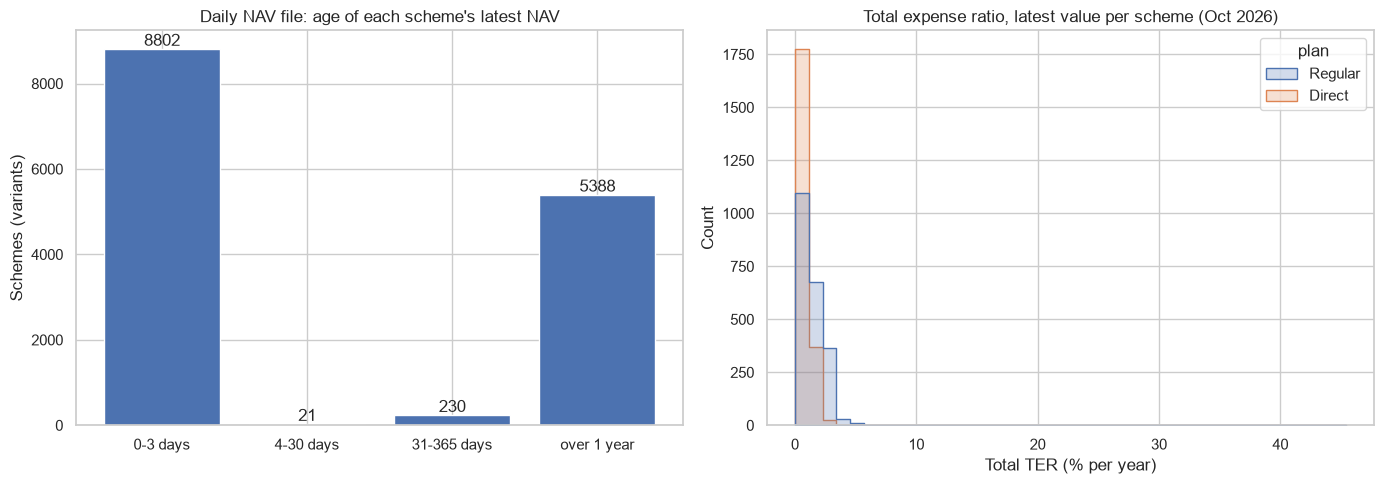

          count  mean   std  min   25%   50%   75%    max
plan                                                     
Direct   2176.0  0.68  1.19  0.0  0.18  0.50  1.02  45.44
Regular  2176.0  1.32  1.05  0.0  0.44  1.13  2.11  16.38


In [29]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: how stale are the rows in the daily NAV file?
age = (daily["nav_date"].max() - daily["nav_date"]).dt.days
buckets = pd.cut(
    age, bins=[-1, 3, 30, 365, 100_000],
    labels=["0-3 days", "4-30 days", "31-365 days", "over 1 year"],
).value_counts().sort_index()
bars = axes[0].bar(buckets.index.astype(str), buckets.values, color="#4C72B0")
axes[0].bar_label(bars)
axes[0].set_title("Daily NAV file: age of each scheme's latest NAV")
axes[0].set_ylabel("Schemes (variants)")

# Right: latest TER per scheme, Regular vs Direct
latest = ter_c.sort_values("TER Date").groupby("NSDL Scheme Code").tail(1)
ter_long = latest.melt(
    value_vars=["Regular Plan - Total TER (%)", "Direct Plan - Total TER (%)"],
    var_name="plan", value_name="ter_pct",
)
ter_long["plan"] = ter_long["plan"].str.split(" Plan").str[0]
sns.histplot(data=ter_long, x="ter_pct", hue="plan", bins=40,
             element="step", ax=axes[1])
axes[1].set_title("Total expense ratio, latest value per scheme (Oct 2026)")
axes[1].set_xlabel("Total TER (% per year)")

plt.tight_layout()
plt.show()

print(ter_long.groupby("plan")["ter_pct"].describe().round(2).to_string())

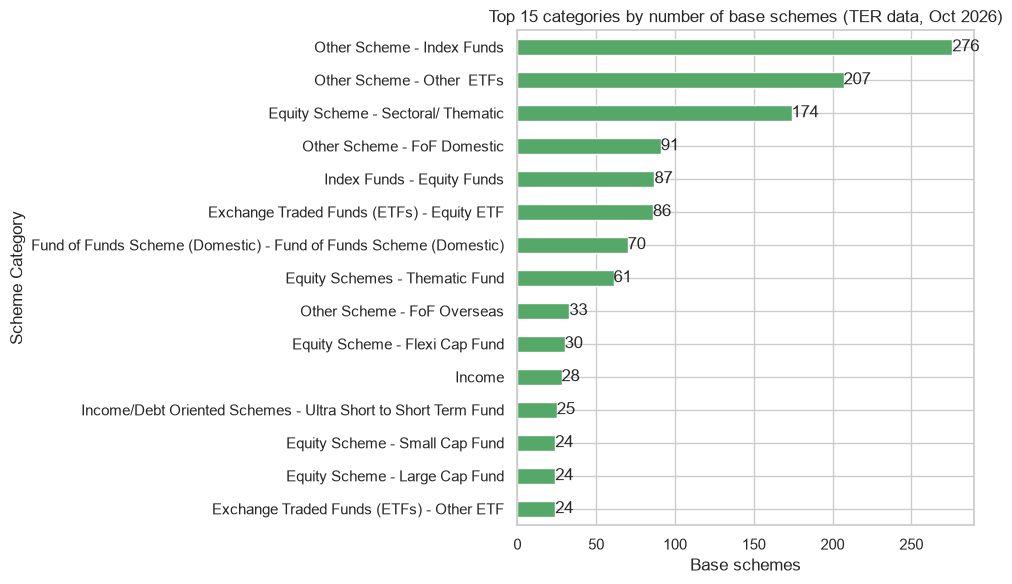

In [30]:
top = latest["Scheme Category"].value_counts().head(15).sort_values()
ax = top.plot.barh(figsize=(10, 6), color="#55A868")
ax.bar_label(ax.containers[0])
ax.set_title("Top 15 categories by number of base schemes (TER data, Oct 2026)")
ax.set_xlabel("Base schemes")
plt.tight_layout()
plt.show()

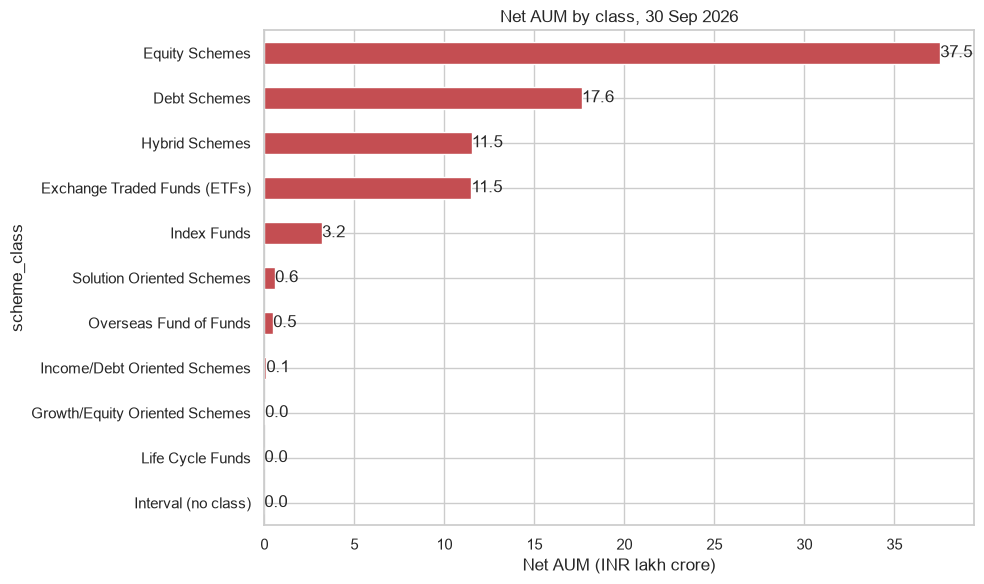

In [31]:
by_class = (aum.groupby("scheme_class", dropna=False)["net_aum_inr_cr"]
               .sum().div(1e5).sort_values())
by_class.index = by_class.index.fillna("Interval (no class)")
ax = by_class.plot.barh(figsize=(10, 6), color="#C44E52")
ax.bar_label(ax.containers[0], fmt="%.1f")
ax.set_title("Net AUM by class, 30 Sep 2026")
ax.set_xlabel("Net AUM (INR lakh crore)")
plt.tight_layout()
plt.show()